In [1]:
# EDA for Jira Ticket Dataset
# This notebook explores the dataset to understand ticket distribution, key teams,
# environments, label patterns, and missing data.
# Data preparation, baseline model, evaluation, and improvements
import re
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

In [2]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [3]:
# Load dataset
df = pd.read_csv("jira tickets dataset.csv")

In [4]:
# 1) Basic dataset overview
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nFirst 5 rows:")
print(df.head().to_string(index=False))

Shape: (100, 12)

Columns:
['ticket_id', 'summary', 'description', 'team', 'system_environment', 'label1', 'label2', 'label3', 'label4', 'cascading1', 'cascading2', 'cascading3']

Data types:
 ticket_id             str
summary               str
description           str
team                  str
system_environment    str
label1                str
label2                str
label3                str
label4                str
cascading1            str
cascading2            str
cascading3            str
dtype: object

Missing values:
 ticket_id              0
summary                0
description            0
team                   0
system_environment     0
label1                 0
label2                 0
label3                55
label4                 0
cascading1             0
cascading2             0
cascading3            43
dtype: int64

Duplicate rows: 0

First 5 rows:
ticket_id                                       summary                                                             


Team distribution:
 team
opsteam         28
datateam        23
supportteam     22
devteam         15
securityteam    12
Name: count, dtype: int64


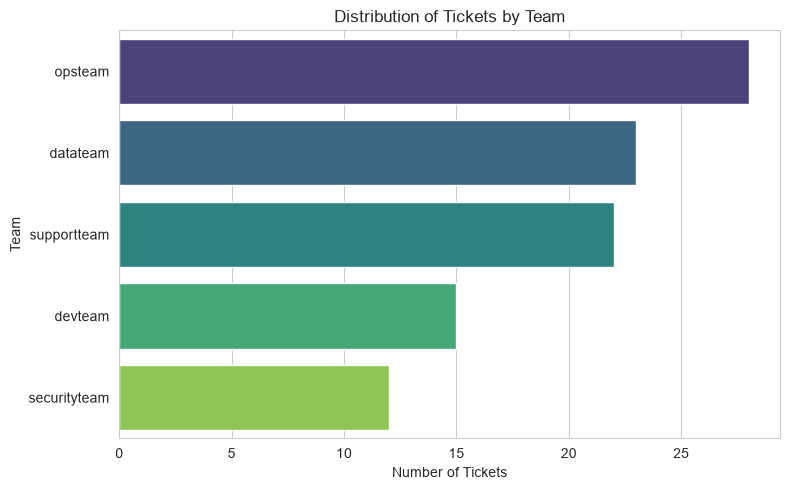

In [5]:
# 2) Distribution by team
team_counts = df["team"].value_counts()
print("\nTeam distribution:\n", team_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, y="team", order=team_counts.index, palette="viridis")
plt.title("Distribution of Tickets by Team")
plt.xlabel("Number of Tickets")
plt.ylabel("Team")
plt.tight_layout()
plt.show()


System environment distribution:
 system_environment
Test          29
Production    28
Dev           25
Acceptance    18
Name: count, dtype: int64


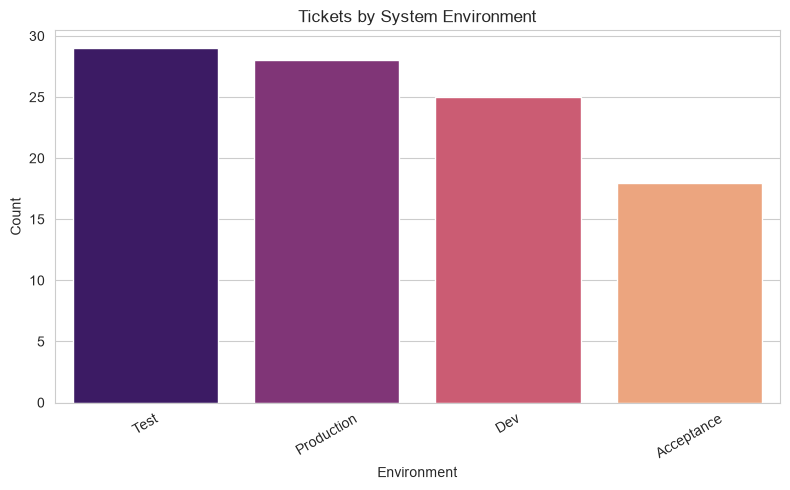

In [6]:
# 3) Distribution by environment
env_counts = df["system_environment"].value_counts()
print("\nSystem environment distribution:\n", env_counts)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="system_environment", order=env_counts.index, palette="magma")
plt.title("Tickets by System Environment")
plt.xlabel("Environment")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [7]:
# 4) Label frequency analysis
label_columns = ["label1", "label2", "label3", "label4", "cascading1", "cascading2", "cascading3"]

label_summary = {}
for col in label_columns:
    counts = df[col].value_counts(dropna=False)
    label_summary[col] = counts
    print(f"\n{col} distribution:\n{counts.head(10)}")


label1 distribution:
label1
fixedfee             71
time and material    29
Name: count, dtype: int64

label2 distribution:
label2
regular work    55
incident        42
project          3
Name: count, dtype: int64

label3 distribution:
label3
NaN         55
urgent      29
audit        8
sla-risk     8
Name: count, dtype: int64

label4 distribution:
label4
internal    73
external    27
Name: count, dtype: int64

cascading1 distribution:
cascading1
jira           12
deployment     11
reporting      10
access          9
security        8
performance     8
backup          7
data            6
integration     6
network         5
Name: count, dtype: int64

cascading2 distribution:
cascading2
power bi          10
vpn                5
release            5
form               5
automation         4
vulnerability      4
windows server     4
configuration      4
restore            4
certificate        4
Name: count, dtype: int64

cascading3 distribution:
cascading3
NaN               43
new feature

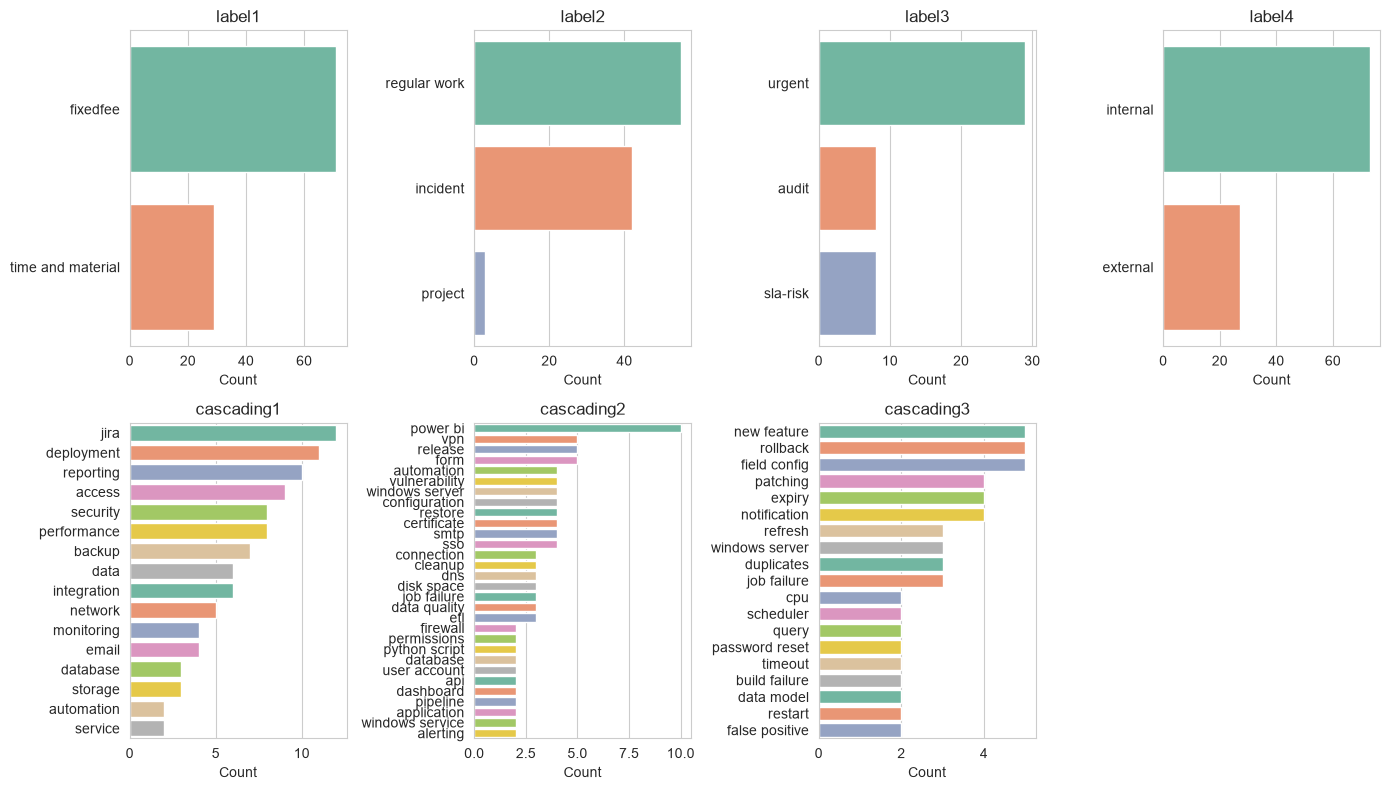

In [8]:
# Plot labels side by side
plt.figure(figsize=(14, 8))
for i, col in enumerate(label_columns, 1):
    plt.subplot(2, 4, i)
    series = df[col].value_counts(dropna=False)
    sns.barplot(x=series.values, y=series.index, palette="Set2")
    plt.title(col)
    plt.xlabel("Count")
    plt.ylabel("")
plt.tight_layout()
plt.show()

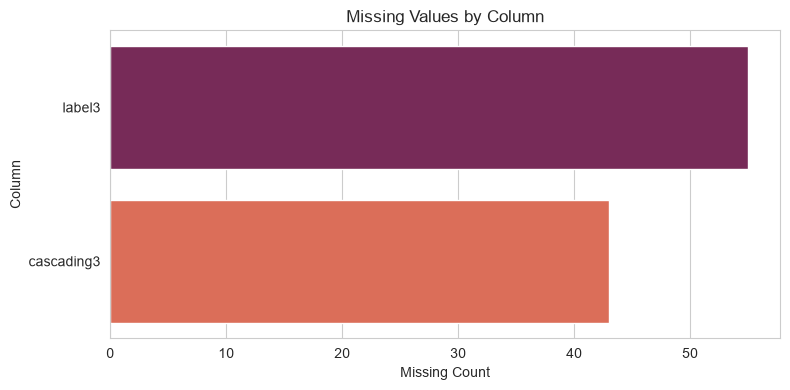

In [9]:
# 5) Missing values visualization
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]

if not missing.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing.values, y=missing.index, palette="rocket")
    plt.title("Missing Values by Column")
    plt.xlabel("Missing Count")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("\nNo missing values found in the dataset.")


Summary length stats:
 count    100.000000
mean      33.010000
std        6.135663
min       22.000000
25%       28.000000
50%       33.000000
75%       36.000000
max       50.000000
Name: summary_length, dtype: float64

Description length stats:
 count    100.000000
mean     122.760000
std       15.451534
min       98.000000
25%      112.000000
50%      119.000000
75%      135.000000
max      164.000000
Name: description_length, dtype: float64


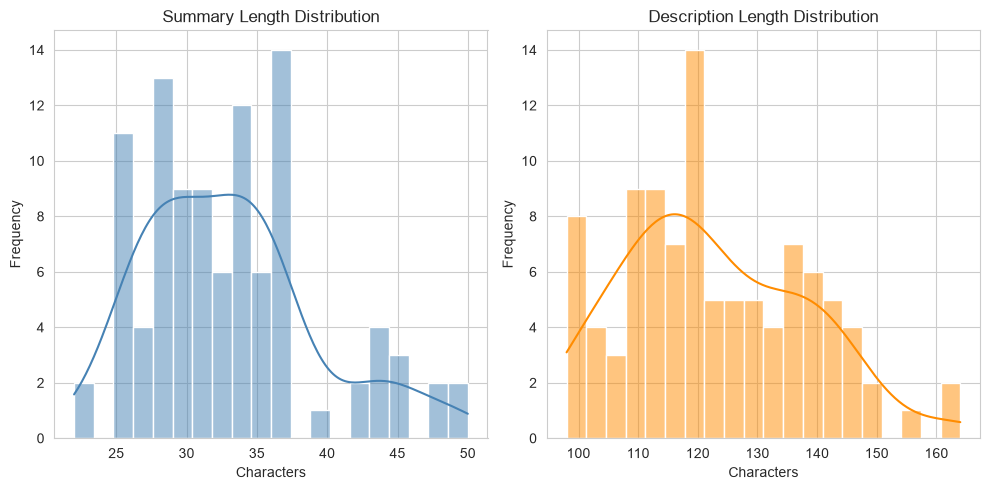

In [10]:
# 6) Ticket text length insights (optional but useful for EDA)
df["summary_length"] = df["summary"].fillna("").str.len()
df["description_length"] = df["description"].fillna("").str.len()

print("\nSummary length stats:\n", df["summary_length"].describe())
print("\nDescription length stats:\n", df["description_length"].describe())

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.histplot(df["summary_length"], bins=20, kde=True, color="steelblue")
plt.title("Summary Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
sns.histplot(df["description_length"], bins=20, kde=True, color="darkorange")
plt.title("Description Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [11]:
# 7) Summary of key observations
print("\nKey EDA observations:")
print("- Team distribution is useful for understanding workload concentration across departments.")
print("- System environment distribution helps identify which operational platforms are most affected.")
print("- Label and cascading columns show the classification patterns used across tickets.")
print("- Missing value checks help determine if data cleaning is required before modeling.")
print("- Text length analysis highlights the richness and variability of ticket descriptions.")



Key EDA observations:
- Team distribution is useful for understanding workload concentration across departments.
- System environment distribution helps identify which operational platforms are most affected.
- Label and cascading columns show the classification patterns used across tickets.
- Missing value checks help determine if data cleaning is required before modeling.
- Text length analysis highlights the richness and variability of ticket descriptions.


In [24]:
df.head()

,ticket_id,summary,description,team,system_environment,label1,label2,label3,label4,cascading1,cascading2,cascading3,summary_length,description_length,text,cascading_path
0,CD-2557,Jira automation rule not firing,The automation rule that assigns new tickets t...,supportteam,test,time and material,incident,none,external,jira,automation,none,31,107,jira automation rule not firing the automation...,jira > automation
1,CD-2576,Critical patches pending on APP-SRV01,Vulnerability scan shows missing critical Wind...,securityteam,acceptance,fixedfee,regular work,none,external,security,vulnerability,patching,37,119,critical patches pending on app srv01 vulnerab...,security > vulnerability > patching
2,CD-2290,New dashboard for capacity planning requested,Management wants a new dashboard showing capac...,datateam,test,fixedfee,project,urgent,internal,reporting,power bi,new feature,45,118,new dashboard for capacity planning requested ...,reporting > power bi > new feature
3,CD-2559,VPN connection drops every hour,Remote users get disconnected from the VPN eve...,opsteam,acceptance,fixedfee,incident,urgent,internal,access,vpn,none,31,123,vpn connection drops every hour remote users g...,access > vpn
4,CD-2611,Critical patches pending on BATCH-SRV02,Vulnerability scan shows missing critical Wind...,securityteam,acceptance,time and material,regular work,none,internal,security,vulnerability,patching,39,121,critical patches pending on batch srv02 vulner...,security > vulnerability > patching


# 1) Prepare the data
Combine summary + description into one text field
Fill empty targets with "none"
Clean text (lowercase, strip punctuation)

In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

for col in ["summary", "description", "team", "system_environment"]:
    df[col] = df[col].fillna("none")

df["text"] = df["summary"].fillna("") + " " + df["description"].fillna("")
df["text"] = df["text"].apply(clean_text)
df["team"] = df["team"].astype(str).str.lower().apply(clean_text)
df["system_environment"] = df["system_environment"].astype(str).str.lower().apply(clean_text)


In [13]:
# Keep the target columns we want to predict
label_cols = ["label1", "label2", "label3", "label4", "cascading1", "cascading2", "cascading3"]
for col in label_cols:
    df[col] = df[col].fillna("none").astype(str).str.lower().apply(clean_text)

# Optional combined cascading target to test on path prediction
# Example: "performance > windows server"
df["cascading_path"] = (
    df[["cascading1", "cascading2", "cascading3"]]
    .fillna("none")
    .astype(str)
    .apply(lambda row: " > ".join([x for x in row if x not in ["none", "nan"]]), axis=1)
)

In [14]:
# Build text features that include team and environment as contextual signals
X = df["text"] + " " + df["team"] + " " + df["system_environment"]
y = df[label_cols]

In [15]:
# 80/20 split (stratified on the first label when possible)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y["label1"]
)

In [16]:
# 2) Baseline: TF-IDF + Logistic Regression + MultiOutputClassifier
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", MultiOutputClassifier(LogisticRegression(max_iter=2000, solver="liblinear")))
])

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", MultiOutputClassifier(LogisticRegression(max_iter=2000, solver="lbfgs")))
])

baseline.fit(X_train, y_train)
y_pred = baseline.predict(X_test)
y_pred = baseline.predict(X_test)


In [17]:
# 3) Evaluate: accuracy and macro F1 per target
print("Baseline model: TF-IDF + LogisticRegression (MultiOutputClassifier)")
for i, col in enumerate(label_cols):
    acc = accuracy_score(y_test[col], y_pred[:, i])
    f1 = f1_score(y_test[col], y_pred[:, i], average="macro", zero_division=0)
    print(f"\n{col}: accuracy={acc:.3f}, macro_f1={f1:.3f}")
    print(classification_report(y_test[col], y_pred[:, i], digits=3, zero_division=0))
    print("Confusion matrix:\n", confusion_matrix(y_test[col], y_pred[:, i]))

Baseline model: TF-IDF + LogisticRegression (MultiOutputClassifier)

label1: accuracy=0.550, macro_f1=0.355
                   precision    recall  f1-score   support

         fixedfee      0.647     0.786     0.710        14
time and material      0.000     0.000     0.000         6

         accuracy                          0.550        20
        macro avg      0.324     0.393     0.355        20
     weighted avg      0.453     0.550     0.497        20

Confusion matrix:
 [[11  3]
 [ 6  0]]

label2: accuracy=0.600, macro_f1=0.371
              precision    recall  f1-score   support

    incident      0.667     0.286     0.400         7
     project      0.000     0.000     0.000         2
regular work      0.588     0.909     0.714        11

    accuracy                          0.600        20
   macro avg      0.418     0.398     0.371        20
weighted avg      0.557     0.600     0.533        20

Confusion matrix:
 [[ 2  0  5]
 [ 0  0  2]
 [ 1  0 10]]

label3: accuracy=0.

In [18]:
# 4) Try a few other models to improve the baseline
# Linear SVM
def build_model(model_name):
    if model_name == "linear_svm":
        return Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
            ("clf", MultiOutputClassifier(LinearSVC()))
        ])
    if model_name == "random_forest":
        return Pipeline([
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
            ("clf", MultiOutputClassifier(RandomForestClassifier(n_estimators=200, random_state=42)))
        ])
    return baseline

for model_name in ["linear_svm", "random_forest"]:
    model = build_model(model_name)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\n=== {model_name.upper()} ===")
    for i, col in enumerate(label_cols):
        acc = accuracy_score(y_test[col], pred[:, i])
        f1 = f1_score(y_test[col], pred[:, i], average="macro", zero_division=0)
        print(f"{col}: accuracy={acc:.3f}, macro_f1={f1:.3f}")


=== LINEAR_SVM ===
label1: accuracy=0.500, macro_f1=0.405
label2: accuracy=0.700, macro_f1=0.750
label3: accuracy=0.650, macro_f1=0.405
label4: accuracy=0.500, macro_f1=0.333
cascading1: accuracy=0.850, macro_f1=0.722
cascading2: accuracy=0.850, macro_f1=0.733
cascading3: accuracy=0.800, macro_f1=0.640

=== RANDOM_FOREST ===
label1: accuracy=0.500, macro_f1=0.405
label2: accuracy=0.800, macro_f1=0.560
label3: accuracy=0.500, macro_f1=0.179
label4: accuracy=0.650, macro_f1=0.394
cascading1: accuracy=0.900, macro_f1=0.891
cascading2: accuracy=0.900, macro_f1=0.851
cascading3: accuracy=0.700, macro_f1=0.569


In [19]:
# 5) Optional: predict the combined cascading path
X_path = df["text"] + " " + df["team"] + " " + df["system_environment"]
y_path = df["cascading_path"]
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_path, y_path, test_size=0.4, random_state=42
)

path_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, solver="liblinear"))
])
path_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
    ("clf", LogisticRegression(max_iter=2000, solver="lbfgs"))
])
path_model.fit(X_train_p, y_train_p)
path_pred = path_model.predict(X_test_p)
print("\nCombined cascading path accuracy:", accuracy_score(y_test_p, path_pred))
print("Combined cascading path macro F1:", f1_score(y_test_p, path_pred, average="macro", zero_division=0))


Combined cascading path accuracy: 0.5
Combined cascading path macro F1: 0.3668202764976959


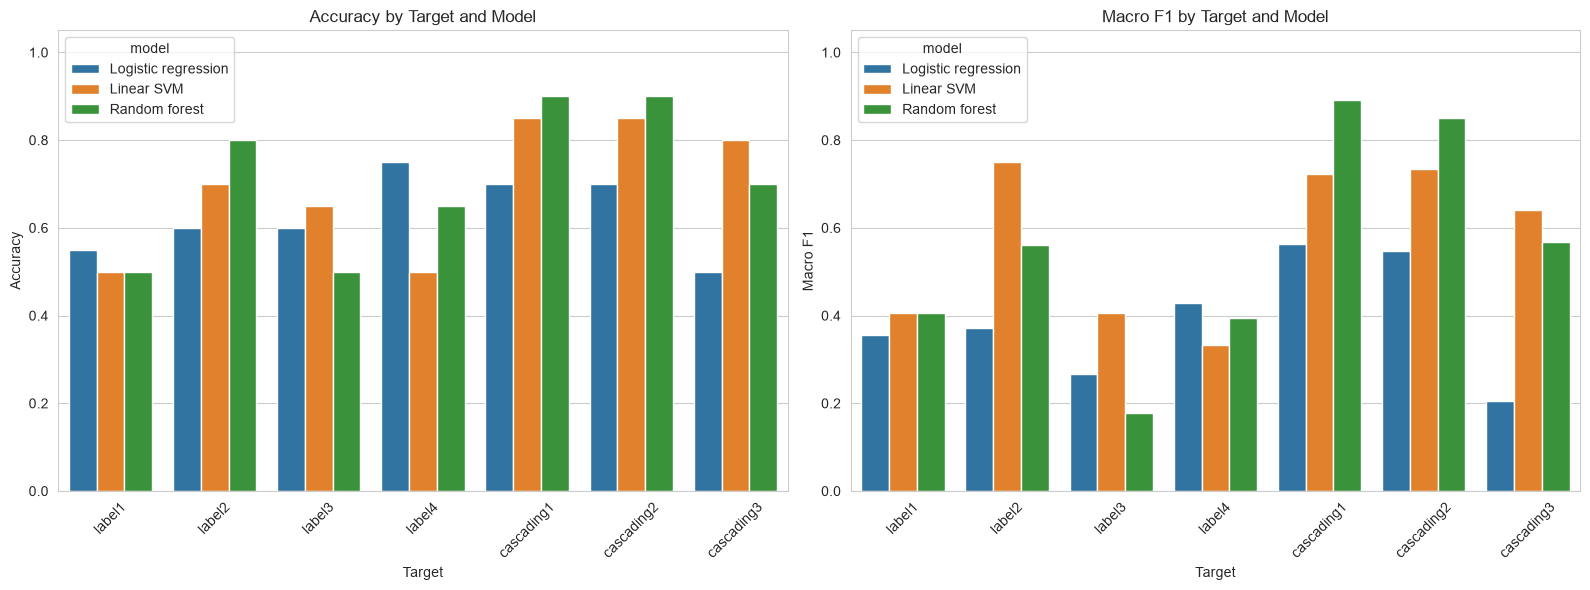

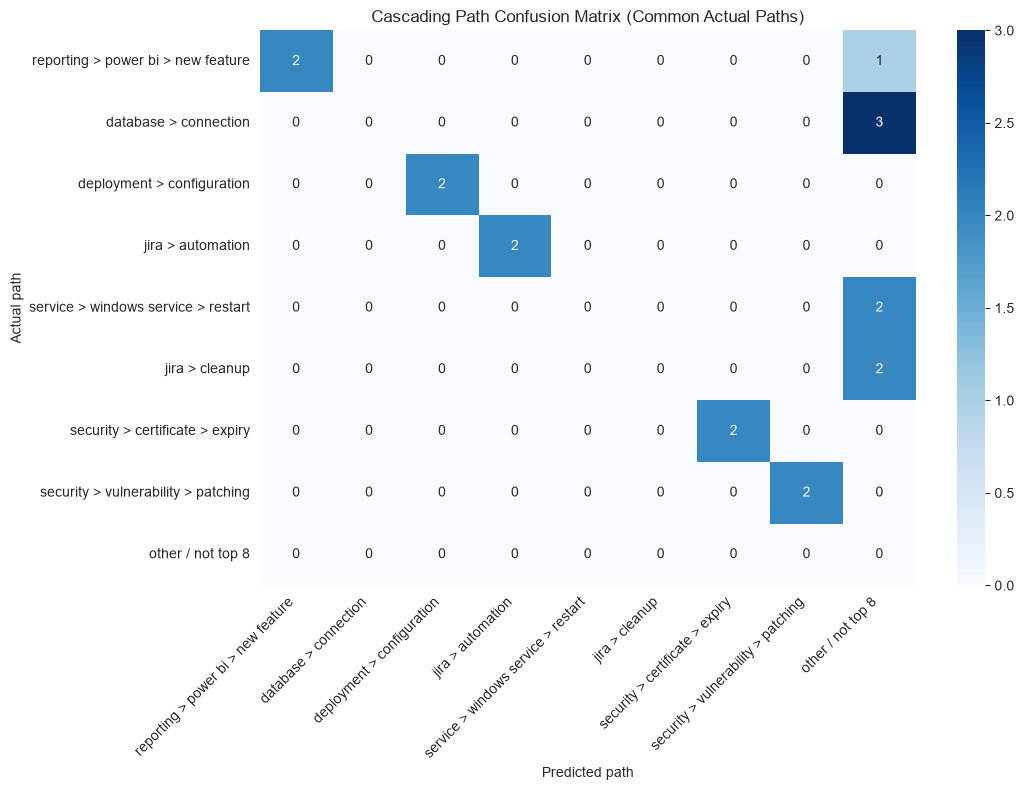

In [23]:
# 5b) Visual model evaluation
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Compare baseline and alternative classifiers across all target columns
visual_models = {
    "Logistic regression": baseline,
    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
        ("clf", MultiOutputClassifier(LinearSVC()))
    ]),
    "Random forest": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")),
        ("clf", MultiOutputClassifier(RandomForestClassifier(n_estimators=200, random_state=42)))
    ])
}

visual_scores = []
for model_name, estimator in visual_models.items():
    if model_name != "Logistic regression":
        estimator.fit(X_train, y_train)
    model_predictions = estimator.predict(X_test)
    for target_index, target_name in enumerate(label_cols):
        visual_scores.append({
            "model": model_name,
            "target": target_name,
            "accuracy": accuracy_score(y_test[target_name], model_predictions[:, target_index]),
            "macro_f1": f1_score(y_test[target_name], model_predictions[:, target_index], average="macro", zero_division=0)
        })

visual_scores = pd.DataFrame(visual_scores)

# Side-by-side target metrics make class imbalance effects easier to spot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=visual_scores, x="target", y="accuracy", hue="model", ax=axes[0])
axes[0].set_title("Accuracy by Target and Model")
axes[0].set_xlabel("Target")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylim(0, 1.05)

sns.barplot(data=visual_scores, x="target", y="macro_f1", hue="model", ax=axes[1])
axes[1].set_title("Macro F1 by Target and Model")
axes[1].set_xlabel("Target")
axes[1].set_ylabel("Macro F1")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 1.05)
fig.tight_layout()
plt.show()

# Show the most common actual paths and group less-common predictions as "other".
# This keeps incorrect predictions visible while keeping the plot readable.
path_predictions = pd.Series(path_pred, index=y_test_p.index)
common_paths = y_test_p.value_counts().head(8).index.tolist()
actual_is_common = y_test_p.isin(common_paths)
actual_common = y_test_p[actual_is_common]
predicted_common_or_other = path_predictions[actual_is_common].where(
    path_predictions[actual_is_common].isin(common_paths), "other / not top 8"
)
path_labels = common_paths + ["other / not top 8"]
path_matrix = confusion_matrix(
    actual_common, predicted_common_or_other, labels=path_labels
)

plt.figure(figsize=(11, 8))
sns.heatmap(
    path_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=path_labels,
    yticklabels=path_labels
)
plt.title("Cascading Path Confusion Matrix (Common Actual Paths)")
plt.xlabel("Predicted path")
plt.ylabel("Actual path")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [20]:
# 6) Check for overfitting on handmade examples
manual_tickets = [
    "VPN connection drops every hour for remote users in the service portal",
    "Critical security patches are missing on APP-SRV01 and need a maintenance window",
    "Users cannot access the dashboard and need a new capacity planning view",
    "Database reports are slow and system performance is down on the production server",
]
manual_df = pd.DataFrame({"summary": manual_tickets, "description": ["" for _ in manual_tickets], "team": ["opsteam", "securityteam", "datateam", "supportteam"], "system_environment": ["internal", "security", "reporting", "production"]})
manual_df["text"] = manual_df["summary"].apply(clean_text) + " " + manual_df["team"].astype(str).str.lower().apply(clean_text) + " " + manual_df["system_environment"].astype(str).str.lower().apply(clean_text)
manual_pred = baseline.predict(manual_df["text"])
manual_df["prediction"] = [dict(zip(label_cols, row)) for row in manual_pred]
print("\nManual ticket predictions:")
print(manual_df[["summary", "prediction"]].to_string(index=False))


Manual ticket predictions:
                                                                          summary                                                                                                                                                              prediction
           VPN connection drops every hour for remote users in the service portal             {'label1': 'fixedfee', 'label2': 'regular work', 'label3': 'none', 'label4': 'internal', 'cascading1': 'access', 'cascading2': 'vpn', 'cascading3': 'none'}
 Critical security patches are missing on APP-SRV01 and need a maintenance window {'label1': 'fixedfee', 'label2': 'regular work', 'label3': 'none', 'label4': 'internal', 'cascading1': 'security', 'cascading2': 'vulnerability', 'cascading3': 'none'}
          Users cannot access the dashboard and need a new capacity planning view    {'label1': 'fixedfee', 'label2': 'regular work', 'label3': 'none', 'label4': 'internal', 'cascading1': 'deployment', 'cascading2': 'power

In [21]:
# 7) Export a few hundred anonymized real tickets and rerun the same pipeline
# real_df.to_csv("real_tickets_anonymized.csv", index=False)
# Then reload and run the exact same pipeline above

# 8) Save the model and wrap a small suggestion function for new tickets
joblib.dump(baseline, "jira_ticket_baseline_model.joblib")

# Suggest labels for a new ticket

def suggest_labels(ticket_text, team="unknown", environment="unknown", model=baseline):
    cleaned = clean_text(ticket_text) + " " + clean_text(team) + " " + clean_text(environment)
    pred = model.predict([cleaned])[0]
    return dict(zip(label_cols, pred))

print("\nExample suggestion:")
print(suggest_labels("Critical Windows patches missing on APP-SRV01 after vulnerability scan", "securityteam", "security"))

# End of notebook pipeline



Example suggestion:
{'label1': 'fixedfee', 'label2': 'regular work', 'label3': 'none', 'label4': 'internal', 'cascading1': 'security', 'cascading2': 'vulnerability', 'cascading3': 'none'}


#Conclusion: The model pipeline works, but the results are not yet reliable enough for real ticket classification. The logistic-regression baseline gets 50–75% accuracy across targets, while macro F1 is lower (about 0.21–0.56), showing that it performs unevenly across classes. For example, it predicts label4 as internal throughout the test set, missing all external tickets.  

#The combined cascading-path model scores 50% accuracy and 0.37 macro F1. The model comparison suggests SVM or random forest may help on some targets, but neither is consistently best.  

These results come from a small synthetic dataset and a test set of only 20 tickets, so treat them as a baseline, not evidence of real-world performance. The next meaningful step is to evaluate the same pipeline on a larger anonymized set of real tickets.  